# **IS4487 Assignment 10: Classification with Decision Trees**

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/vandanara/UofUtah_IS4487/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Case: AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: female; 1: male |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

## **Task 1. Import libraries, Load the Data and Preview it**

1.1. Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib

1.2. Load the data
- Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`)

1.3. Initial Data Understanding - Preview the data
- Describe or profile the dataframe
- Look for any outliers, missing values, or duplicates (enough to describe it)

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns

In [9]:
# Load the historical data from GitHub
url = 'https://raw.githubusercontent.com/vandanara/UofUtah_IS4487/main/DataSets/adviseinvest_historical_data.csv'
df = pd.read_csv(url)


In [10]:
# View basic structure and datatypes of the dataset
print("--- Dataframe Info ---")
df.info()

# Display the first few rows
print("\n--- Head ---")
display(df.head())

# Describe numeric features
print("\n--- Descriptive Statistics ---")
display(df.describe(include='all'))

# Check for missing values
print("\n--- Missing Values ---")
print(df.isnull().sum())

# Check for duplicate rows
print("\n--- Duplicate Count ---")
print(df.duplicated().sum())


--- Dataframe Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   answered        29504 non-null  int64  
 1   income          29504 non-null  int64  
 2   female          29504 non-null  object 
 3   age             29504 non-null  int64  
 4   job             29504 non-null  int64  
 5   num_dependents  29504 non-null  int64  
 6   rent            29504 non-null  int64  
 7   own_res         29504 non-null  int64  
 8   new_car         29502 non-null  float64
 9   chk_acct        29504 non-null  int64  
 10  sav_acct        29504 non-null  int64  
 11  num_accts       29504 non-null  int64  
 12  mobile          29504 non-null  int64  
 13  product         29504 non-null  int64  
dtypes: float64(1), int64(12), object(1)
memory usage: 3.2+ MB

--- Head ---


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
0,1,13520,0,23,0,1,1,0,0.0,0,2,0,1,2
1,0,14780,0,22,2,1,0,1,0.0,3,0,3,0,0
2,1,37570,0,62,2,1,0,0,1.0,3,0,4,0,4
3,0,12450,0,33,2,1,0,1,0.0,1,0,2,0,0
4,0,12400,0,48,1,2,0,0,1.0,2,1,4,0,0



--- Descriptive Statistics ---


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29504.000000,29504.000000,29504,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29502.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000
unique,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,27903,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,0.546638,33766.893303,NaN,34.773454,1.915401,1.140998,0.210412,0.681128,0.240797,1.468547,0.956616,2.458345,0.091106,1.535792
std,0.497829,29379.202710,NaN,11.369865,0.658183,0.348025,0.407608,0.466047,0.427575,1.234727,1.483946,19.497380,0.287765,1.625916
min,0.000000,-65600.000000,NaN,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,13550.000000,NaN,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,1.000000,23310.000000,NaN,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,1.000000,41690.000000,NaN,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000



--- Missing Values ---
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           2
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
product           0
dtype: int64

--- Duplicate Count ---
29035


### ✍️ Please answer the following:

1.1. What stands out in the initial preview? Any columns or rows that seem unusual?


### ✍️ Your Response: 🔧
1.1. The big thing that stands out in the data is the amount of Duplicate counts 29035! We also have 2 missing values in the New Car column and I need to change data type of Female to binary

## **Task 2. Data Preparation**

### **2.1. Data Cleanup**
2.1.1. Delete any obvious outliers

2.1.2. Clean up any missing data. Consider fixing/imputing missing values if you can, OR if too many are missing, perhaps delete the row.

2.1.3. Remove any variables, like customer_id, that are not helpful in predicting the target variable (Hint: are there any variables that are available only AFTER the customer has answered, and shoudl NOT be used in predicting?)

2.1.4 Clean up and save the data in a new dataframe named "df_clean"


In [11]:
# 2.1.1. Delete obvious outliers
# Let's inspect potential outliers in columns like 'income' and 'age'
# Filter out realistic ranges (e.g., age > 0 and age < 120, income >= 0)
df = df[(df['age'] > 0) & (df['age'] < 120)]
df = df[df['income'] >= 0]
display(df.describe())

,answered,income,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29501.000000,29501.000000,29501.000000,29501.000000,29501.000000,29501.000000,29501.000000,29499.000000,29501.000000,29501.000000,29501.000000,29501.000000,29501.000000
mean,0.546659,33772.758212,34.770584,1.915427,1.141012,0.210434,0.681096,0.240754,1.468526,0.956544,2.458391,0.091116,1.535880
std,0.497827,29373.257713,11.356165,0.658194,0.348040,0.407623,0.466060,0.427548,1.234751,1.483974,19.498369,0.287778,1.625947
min,0.000000,2760.000000,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,13550.000000,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,1.000000,23310.000000,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,1.000000,41690.000000,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000
max,1.000000,159450.000000,74.000000,3.000000,2.000000,1.000000,1.000000,1.000000,3.000000,4.000000,3345.000000,1.000000,4.000000


Missing values after cleanup:
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           0
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
product           0
dtype: int64


In [13]:
# 🔧 2.1.3. Remove variables that are not helpful

Remaining columns:
['answered', 'income', 'female', 'age', 'job', 'num_dependents', 'rent', 'own_res', 'new_car', 'chk_acct', 'sav_acct', 'num_accts', 'mobile']


In [14]:
# 🔧 2.1.4. Name the final cleaned dataframe as df_clean

Cleaned DataFrame shape: (29499, 13)
   answered  income female  age  job  num_dependents  rent  own_res  new_car  \
0         1   13520      0   23    0               1     1        0      0.0   
1         0   14780      0   22    2               1     0        1      0.0   
2         1   37570      0   62    2               1     0        0      1.0   
3         0   12450      0   33    2               1     0        1      0.0   
4         0   12400      0   48    1               2     0        0      1.0   

   chk_acct  sav_acct  num_accts  mobile  
0         0         2          0       1  
1         3         0          3       0  
2         3         0          4       0  
3         1         0          2       0  
4         2         1          4       0  


### ✍️ Please answer the following:

2.5 Explain the steps that you took to clean outliers and missing data. Why did you chose the approach that you used?

2.6 Which variables did you remove, and why?

### ✍️ Your Response: 🔧

2.5.

2.6.

### **2.2. Clean up the data types of features. Convert to int**

 2.2.1. Convert any variables that should be an integer into an integer

In [15]:
# 🔧 2.2.1. Convert variables to integer data type

answered          int64
income            int64
female            int64
age               int64
job               int64
num_dependents    int64
rent              int64
own_res           int64
new_car           int64
chk_acct          int64
sav_acct          int64
num_accts         int64
mobile            int64
dtype: object


### **2.3. Clean up the data types of features. Convert to categorical**

2.3.1. Change the target, `answered` to yes/no and make it categorical (boolean with only two categories)

2.3.2. Find at least 5-8 variables that would be appropriate to convert to categories

answered
yes    16125
no     13374
Name: count, dtype: int64
category


answered          category
income               int64
female            category
age                  int64
job               category
num_dependents       int64
rent              category
own_res           category
new_car           category
chk_acct          category
sav_acct          category
num_accts            int64
mobile            category
dtype: object


## **Task 3: Exploratory Data Analysis (EDA)**

### **3.1.-3.5. Draw charts**
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



/tmp/ipykernel_443/3324584169.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='answered', y='income', data=df_clean, palette='Set2')


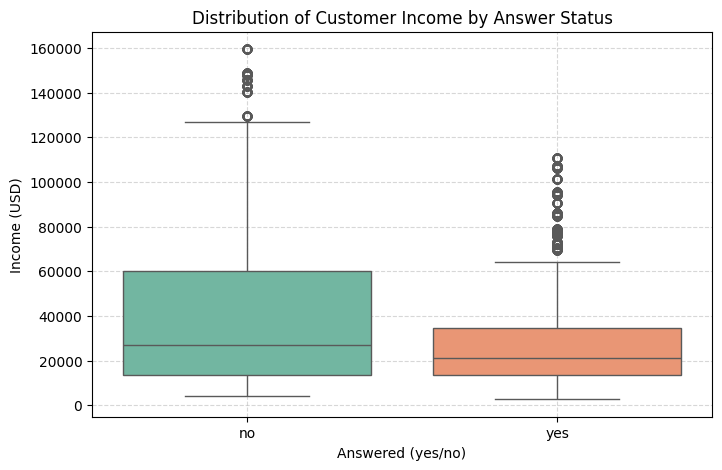

In [18]:
# 🔧3.1. Chart 1

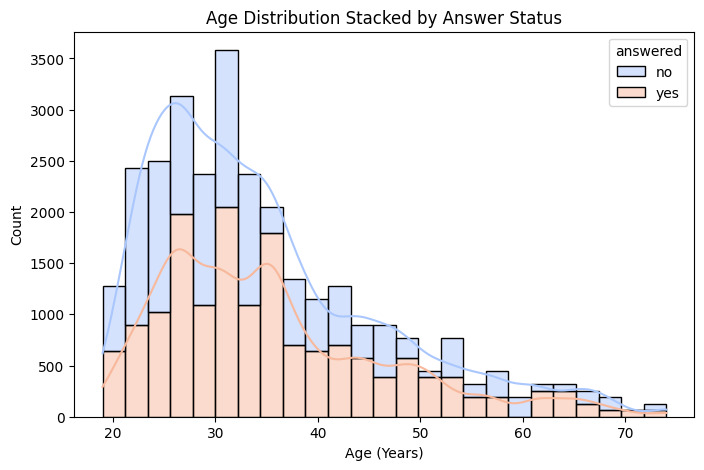

In [19]:
# 🔧3.2. Chart 2

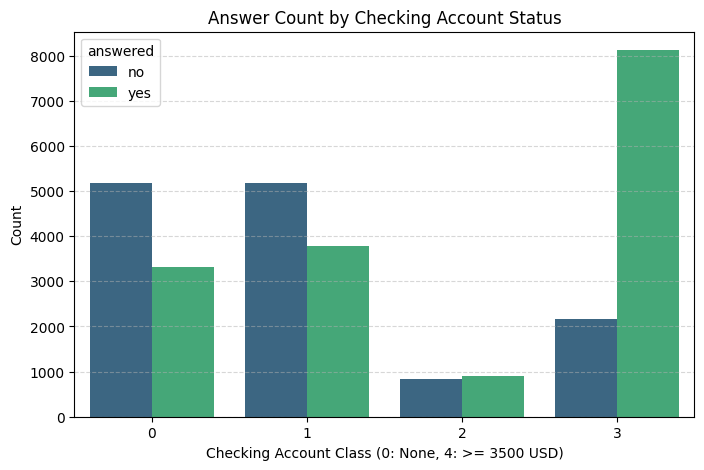

In [20]:
# 🔧3.3. Chart 3

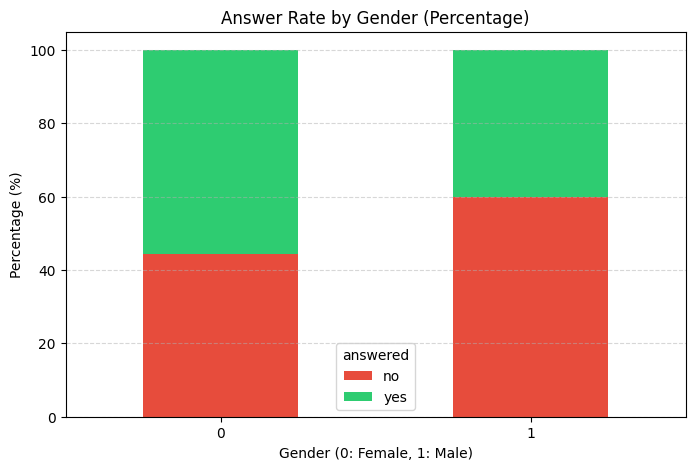

In [21]:
# 🔧3.4. Chart 4

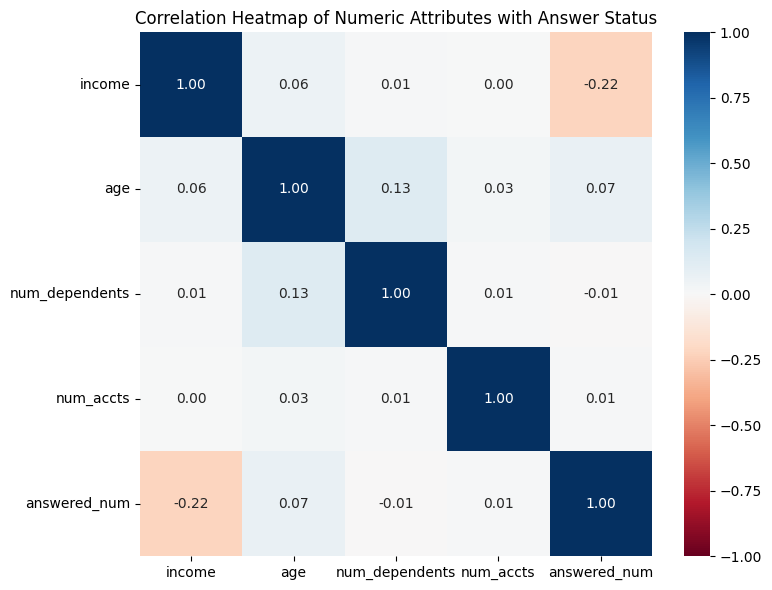

In [22]:
# 🔧3.5. Chart 5

### ✍️ Please answer the following:

3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  

### ✍️ Your Response: 🔧

3.6.

3.7.  

## **Task 4. Modeling**

### **4.1. Calculate the baseline probability of answering**

If we use no model at all, how good is our chance of predicting someone answering?  
* Use a calculation to find the chances of someone answering when called.

Total Customers: 29499
Customers who Answered (Yes): 16125
Baseline Probability of Answering: 0.5466 (54.66%)


### **4.2. Split the training and testing datasets**

Split `df_clean` using `train_test_split()` function
- all variables except `answered` should be in the `X` variable
- `answered` is the `y` variable


X_train shape: (23599, 12)
X_test shape: (5900, 12)
y_train distribution:
answered
yes    0.546633
no     0.453367
Name: proportion, dtype: float64


### **4.3. Create and Visualize a Decision Tree**
4.3.1. Use all available attributes (except those that were eliminated in step 2) to create a decision tree model
- Let us set the following parameters, `criterion` = "entropy" and  `max_depth` = 4

4.3.2. Visualize the tree

In [25]:
# 🔧 4.3.1. Create a Decision Tree

Decision Tree model successfully trained.


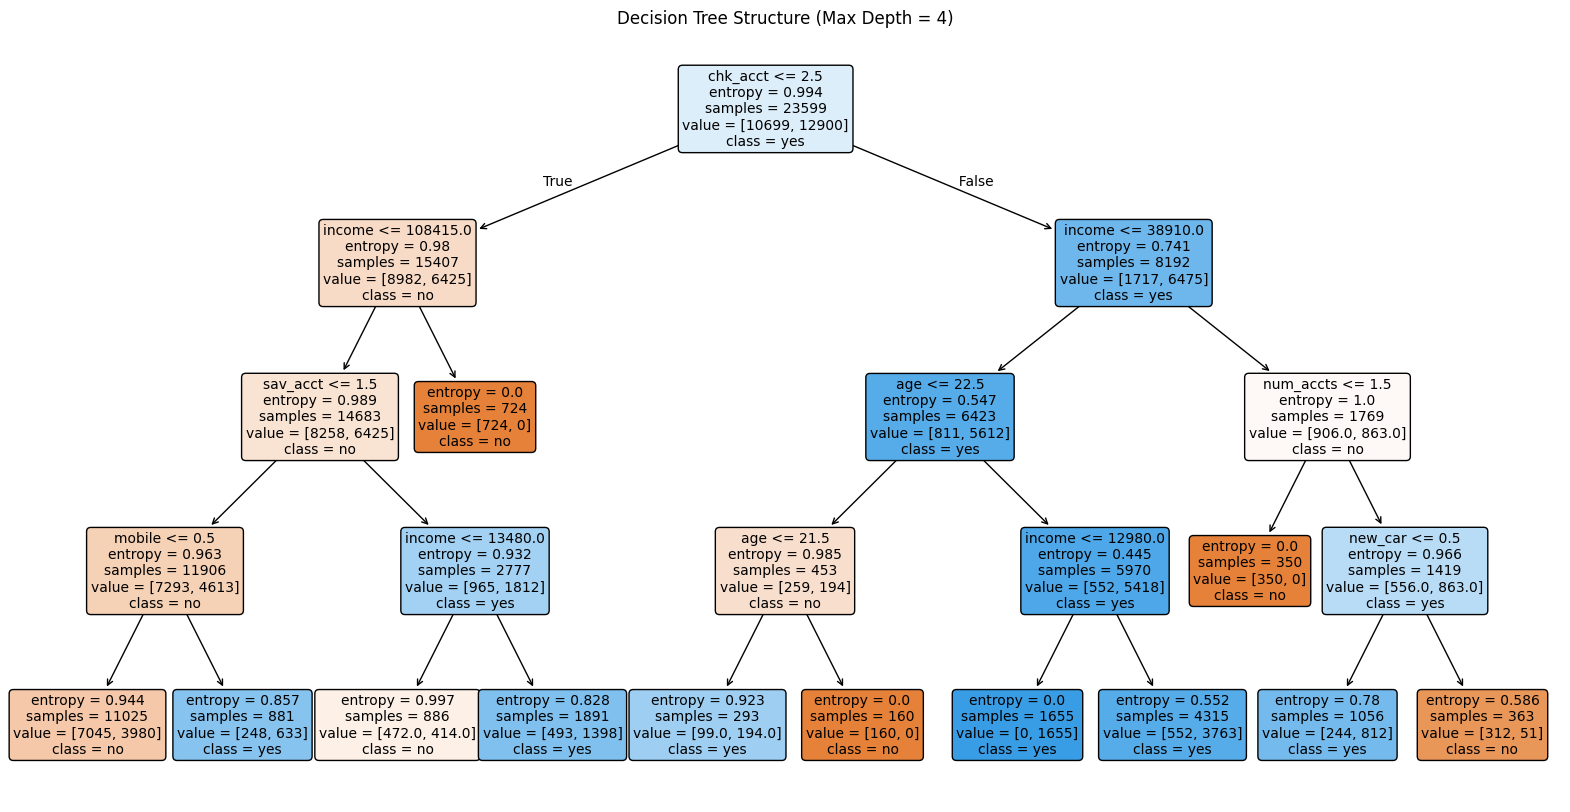

In [26]:
# 🔧 4.3.2. display (visualize) the Tree

### **4.4. What is the accuracy?**

This should be better than the base probability, or you have failed in your objective

In [27]:
# 🔧 4.4.1. Calculate the probability for your tree

Baseline Probability of Answering: 54.66%
Decision Tree Model Accuracy: 72.90%
Difference (Improvement): +18.24%


### ✍️ Please answer the following:

4.4.2. What is the difference between the probability from the model compared to the base probability? Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧

4.4.2.


### **4.5: Create a confusion matrix**

This will show false positives, true positives, false negatives and true negatives.

Confusion Matrix:
[[2199  476]
 [1123 2102]]

True Negatives (TN): 2199
False Positives (FP): 476
False Negatives (FN): 1123
True Positives (TP): 2102


Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

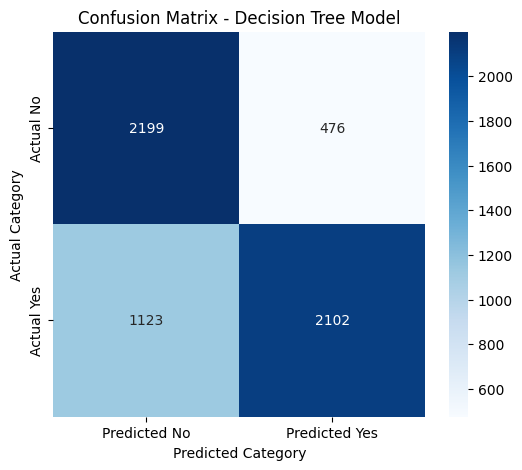

## **Task 5: Evaluate the Model**

Earlier, we calculated the technical accuracy of the model. It is also important to evaluate the model economically. What would be the economic benefit of using this model for the business?

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model `answered` as the target in this case is therefore equivalent to modeling `purchased` as the target.

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- benefit: True answered * 75 -> These people purchased
- cost: False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### **5.1. Calculate the Profit Using the Model**

In [30]:
# 🔧 5.1. Write a calculation for the profit from your model

True Positives (TP): 2102 (Earn $75 each)
False Positives (FP): 476 (Lose $25 each)
Total Benefit: $157,650.00
Total Cost: $11,900.00
Net Profit with the Model: $145,750.00


### **5.2 Compare to the Default Profit**

How much profit (revenue - costs) could be expected if all customers are called? We can consider this a baseline case for profit since it does not require a model.

In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives, treat the customers who do not answer as false positives.

In [31]:
# 🔧 5.2.1. Write a calculation for the overall profit without using the model

Total Customers in Test Set: 5900
Actual Customers who Answered (Yes): 3225 (Earn $75 each)
Actual Customers who Did Not Answer (No): 2675 (Lose $25 each)
Baseline Benefit: $241,875.00
Baseline Cost: $66,875.00
Baseline Profit (Calling All): $175,000.00

Net Profit with Model: $145,750.00
Profit Improvement using the Model: $-29,250.00


### ✍️ Please answer the following:

5.2.2. What is the difference in profit between calling all customers and calling customers that are recommended by the model?

5.2.3. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
5.2.2.

5.2.2

### **5.3 Tune the Model**

5.3.1. Create a new tree by adjusting the parameters such as size or shape of the tree or others

5.3.2. then test the accuracy

Keep changing these parameters until you end up with a tree with accuracy that is **better** than the initial model

In [32]:
# 🔧 5.3.1. Create a new version of the tree with new parameters

Tuned Decision Tree model successfully trained!


In [33]:
# 🔧 5.3.2. Calculate evaluation metrics

Initial Model Accuracy: 72.90%
Tuned Model Accuracy: 79.17%
Improvement: +6.27%

Tuned Model Net Profit: $159,200.00
Change in Profit over Initial Model: $+13450.00


### **5.4 Apply the Model to New Customers**

5.4.1. Import the "adviseinvest_new_customer_data.csv" file

5.4.2. Perform the same data cleanup steps from Step 2 above (we have to do the same pre-processing in test data as we did in training data). Copy paste the code.

5.4.3. Using the **better** tree model you created in task 5.3, predict the target variable for each customer by feeding the new customer data into the model

5.4.4. Predict the number of customers who will answer (or not) for the target variable.

In [34]:
# 🔧 5.4.1. Import new customer data into a new data frame

--- New Customer Data Shape ---
(1000, 13)

--- New Customer Preview ---


,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,customer_id
0,30010,0,40,2,1,1,0,0,1,0,3,0,H1597
1,30510,0,54,2,1,0,1,0,0,0,2,0,P1446
2,12880,0,48,2,2,0,1,0,0,1,4,0,E1492
3,15530,0,44,2,1,0,1,0,0,0,2,0,W5143
4,46230,0,40,3,1,0,1,0,3,1,2,0,W4927


In [36]:
# 🔧 5.4.2. Apply the above best model, Predict the number of customers who will be yes/no for the target variable

Dropping non-predictive identifier columns: ['customer_id']

--- Predictions on New Customers ---
Predicted 'no': 579 customers (57.90%)
Predicted 'yes': 421 customers (42.10%)


## **Task 6: Conclusion**

### ✍️ Please answer the following:

6.1. Did we improve our profit using the model?

6.2: How else could the model be utilized by the business?


### ✍️ Your Response:

6.1.   

6.2.



## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Save the file with your last name and first name as shown below (see detailed instructions in Lab 1 on how to do this).
- Submit the assignment as an **HTML file** on Canvas


In [ ]:
!jupyter nbconvert --to html "assignment_10_LastnameFirstname.ipynb"